# 01 · Configuration and randomness

This notebook explains:

1. the **config file**: sections, defaults, validation, relative paths, overrides;
2. **distribution specs**: how a random parameter is written in the config;
3. **seeds and random streams**: how every image and every module gets its own random numbers,
   and why this makes debugging easier.

Code: `nxgen/core/config.py`, `nxgen/core/rng.py`.

In [1]:
from _setup import *
import json
from nxgen.core import config as C
from nxgen.core import rng as R

## 1. The config file

One JSON file holds every setting, grouped in **sections**, one per module. The offline
launcher (templates) and the online generator read the same file; each uses its own sections.

All sections and keys, with their default values, are in `DEFAULTS`:

In [2]:
for section, keys in C.DEFAULTS.items():
    print(f'{section:15s}', json.dumps(keys))

grid            {"target_voxel_mm": 0.6}
labels          {"tree": null, "background": 0, "unassigned": "error", "output_labels": "templates"}
template        {"hr_voxel_mm": 0.2, "sigma_mm": 0.0, "margin_mm": 16.0}
patch           {"size": null}
acquisition     {"lowres_prob": 0.95, "iso_prob": 0.1, "max_iso_mm": 4.0, "max_aniso_mm": 8.0, "alpha": [0.970873786407767, 1.03], "random_thickness": true, "contrasts": null}
morphology      {"pairs": [], "n_iter": {"randint": [1, 4]}, "prob": 0.5}
spatial         {"rotation_deg": [-10.0, 10.0], "zoom": [0.9, 1.1], "shear": 0.0, "translation_mm": 0.0, "elastic_dmax_mm": 7.5, "elastic_ctrl": {"randint": [2, 7]}}
partial_volume  {"method": "downsample", "top_k": 8, "smooth_sigma_vox": 0.5}
tree            {"colors_mu": [0.0, 255.0], "colors_sigma": [0.255, 2.55], "min_sigma": 0.0, "intensity_scale": 255.0, "resolution": "acquisition"}
bias            {"prob": 1.0, "vmax": 0.5, "ctrl": 5}
motion          {"prob": 0.3, "shots": 3, "rotation_deg": 

Every key is documented in two places: the comment above it in `nxgen/core/config.py` and the
tables of `docs/config.md`.

A config file only needs the values that **differ** from the defaults. This is the NextBrain
config used in the notebooks:

In [3]:
print(open(CONFIG).read())

{
  "grid": {
    "target_voxel_mm": 0.4
  },
  "labels": {
    "tree": "../data/inputs/nextbrain_complete_tree.json",
    "background": 0,
    "unassigned": "background",
    "output_labels": "templates"
  },
  "template": {
    "hr_voxel_mm": 0.2,
    "sigma_mm": 0.1,
    "margin_mm": 4.0
  },
  "patch": {
    "size": null
  },
  "acquisition": {
    "lowres_prob": 0.5,
    "iso_prob": 0.2,
    "max_iso_mm": 1.0,
    "max_aniso_mm": 1.0,
    "alpha": [
      0.970873786407767,
      1.03
    ],
    "random_thickness": true,
    "contrasts": null
  },
  "morphology": {
    "pairs": [
      [
        "background_l1",
        "cerebral_gm_l1"
      ],
      [
        "background_l1",
        "cerebellar_gm_l1"
      ],
      [
        "cerebral_gm_l1",
        "cerebral_wm_l1"
      ],
      [
        "cerebellar_gm_l1",
        "cerebellar_wm_l1"
      ],
      [
        "cerebral_wm_l1",
        "csf_ventricles_l1"
      ],
      [
        "cerebral_wm_l1",
        "deep_gm_l1"
      

## 2. Loading: `load_config`

`load_config(path, **overrides)` builds the complete config in three layers, later wins:

1. `DEFAULTS`
2. the JSON file
3. keyword overrides, one dict per section (only the given keys are replaced)

It returns a plain dict with **every** section and key, so code never has to guess defaults.

In [4]:
cfg = C.load_config(CONFIG, noise={'sigma': 0.0}, patch={'size': [96, 96, 96]})
print('noise         :', cfg['noise'])            # sigma overridden, space from the file
print('patch         :', cfg['patch'])
print('normalization :', cfg['normalization'])    # only defaults
print('tree path     :', cfg['labels']['tree'])   # made absolute

noise         : {'sigma': 0.0, 'space': 'lowres'}
patch         : {'size': [96, 96, 96]}
normalization : {'method': 'minmax', 'percentiles': [0.5, 99.5]}
tree path     : /home/agustin/phd/synthseg_nextbrain/project/dev/wp3/generator_v2_modular/data/inputs/nextbrain_complete_tree.json


**Relative paths** (`labels.tree`) are relative to the *config file*, not to the folder you
run from, so a config and its tree can move together.

## 3. Validation: mistakes raise immediately

Typos and invalid values never pass silently. `load_config` checks:

* unknown sections and keys;
* keys with a fixed set of options (`CHOICES`);
* distribution specs (`SPECS`);
* probabilities in [0, 1], patch size, morphology pairs, etc.

In [5]:
print('options checked:', {f'{s}.{k}': v for (s, k), v in C.CHOICES.items()})
print('specs checked  :', C.SPECS)
print()
bad_configs = [
    dict(nosie={'sigma': 0.1}),                        # unknown section
    dict(noise={'sgma': 0.1}),                         # unknown key
    dict(noise={'space': 'middle'}),                   # invalid option
    dict(labels={'unassigned': 'background_l1'}),      # the value of the v2 NextBrain config
    dict(spatial={'zoom': [1.1, 0.9]}),                # lo > hi
    dict(bias={'prob': 1.5}),                          # probability > 1
    dict(patch={'size': [64, 64]}),                    # needs 3 values
]
for bad in bad_configs:
    try:
        C.load_config(**bad)
        print('ACCEPTED (unexpected):', bad)
    except ValueError as e:
        print(f'{json.dumps(bad):45s} -> {e}')

options checked: {'labels.unassigned': ('error', 'background'), 'labels.output_labels': ('templates', 'tree'), 'partial_volume.method': ('downsample', 'smooth'), 'noise.space': ('lowres', 'highres'), 'normalization.method': ('minmax', 'percentile', 'none')}
specs checked  : {'morphology': ('n_iter',), 'spatial': ('rotation_deg', 'zoom', 'shear', 'translation_mm', 'elastic_dmax_mm', 'elastic_ctrl'), 'tree': ('colors_mu', 'colors_sigma'), 'motion': ('rotation_deg', 'translation_mm'), 'noise': ('sigma',)}

{"nosie": {"sigma": 0.1}}                     -> Unknown config section 'nosie'; known: ['acquisition', 'bias', 'grid', 'labels', 'morphology', 'motion', 'noise', 'normalization', 'partial_volume', 'patch', 'spatial', 'template', 'tree']
{"noise": {"sgma": 0.1}}                      -> Unknown config key noise.sgma; known: ['sigma', 'space']
{"noise": {"space": "middle"}}                -> noise.space must be one of ('lowres', 'highres'), got 'middle'
{"labels": {"unassigned": "backgrou

The fourth case is the real v2 file (`nextbrain_configs.json`): v2 accepted
`"background_l1"` without complaint and behaved as `"background"`. Here it is an error.

## 4. Config hash

`config_hash(cfg)` is a short hash of the complete config. Every plan stores it, and the CLI
saves each config used in a dataset under `configs/<hash>/`, so each image points to the exact
settings it was generated with.

In [6]:
print(C.config_hash(C.load_config(CONFIG)))
print(C.config_hash(C.load_config(CONFIG, noise={'sigma': 0.0})))   # any change -> new hash

612a035fc7
655a19a2d7


## 5. Distribution specs

A random parameter is written as a **distribution spec**:

| JSON | Meaning |
|---|---|
| `5.0` | fixed value (nothing is drawn) |
| `[lo, hi]` | uniform in [lo, hi] |
| `{"uniform": [lo, hi]}` | same, explicit |
| `{"randint": [lo, hi]}` | integer in [lo, hi], both included |
| `{"choice": [a, b, ...]}` | one of the values, equally likely |

`draw(spec, rng)` returns one value. A fixed number **pins** the parameter: this is how a config
gives predictable results (e.g. `"rotation_deg": 0` for no rotation, `"rotation_deg": 15` for
exactly 15 degrees).

In [7]:
rng = np.random.default_rng(0)
specs = {'5.0': 5.0, '[0.9, 1.1]': [0.9, 1.1], '{"randint": [2, 7]}': {'randint': [2, 7]},
         '{"choice": ["T1", "T2"]}': {'choice': ['T1', 'T2']}}
for text, spec in specs.items():
    print(f'{text:26s} ->', [R.draw(spec, rng) for _ in range(8)])

5.0                        -> [5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0]
[0.9, 1.1]                 -> [1.027392337464291, 0.9539573427527741, 0.908194704787239, 0.9033055271057059, 1.0626540478400546, 1.0825511154555445, 1.021327155153436, 1.0458993121967997]
{"randint": [2, 7]}        -> [5, 5, 5, 7, 3, 6, 6, 2]
{"choice": ["T1", "T2"]}   -> ['T1', 'T2', 'T2', 'T1', 'T2', 'T2', 'T2', 'T1']


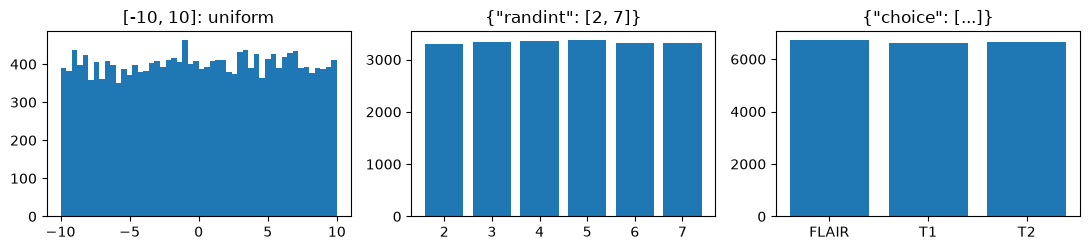

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))
axes[0].hist([R.draw([-10, 10], rng) for _ in range(20000)], 50)
axes[0].set_title('[-10, 10]: uniform')
vals = [R.draw({'randint': [2, 7]}, rng) for _ in range(20000)]
axes[1].bar(*np.unique(vals, return_counts=True))
axes[1].set_title('{"randint": [2, 7]}')
vals = [R.draw({'choice': ['T1', 'T2', 'FLAIR']}, rng) for _ in range(20000)]
axes[2].bar(*np.unique(vals, return_counts=True))
axes[2].set_title('{"choice": [...]}')
plt.tight_layout(); plt.show()

**Change from v2.** In v2, `"rotations": 10` meant "uniform in [-10, 10]". Here ranges are
explicit: `"rotation_deg": [-10, 10]`. `"rotation_deg": 10` means exactly 10 degrees.

Parameters drawn **per axis** (rotation, zoom, shear, translation) draw one value per axis
from the same spec.

Invalid specs are rejected by `check_spec` (called by `load_config`):

In [9]:
for bad in ([2, 1], {'randint': [3]}, {'choice': []}, True, 'abc', {'normal': [0, 1]}):
    try:
        R.check_spec(bad, 'example')
    except ValueError as e:
        print(e)

example: a range must be [lo, hi] with lo <= hi, got [2, 1]
example: randint needs [lo, hi], got [3]
example: empty choice
example: booleans are not distribution specs
example: invalid distribution spec 'abc' (number, [lo, hi], {'uniform': ...}, {'randint': ...} or {'choice': [...]})
example: invalid distribution spec {'normal': [0, 1]} (number, [lo, hi], {'uniform': ...}, {'randint': ...} or {'choice': [...]})


## 6. Seeds

Each image has one **image seed**. In a run with seed `run_seed`, image `i` uses
`image_seed(run_seed, i)`, an independent 32-bit number (numpy `SeedSequence`). Image 42 can
therefore be regenerated alone, without generating images 0-41.

In [10]:
print([R.image_seed(0, i) for i in range(5)])
print('same inputs, same seed:', R.image_seed(0, 42) == R.image_seed(0, 42))

[2968811710, 3964924996, 3141116543, 2613022947, 1874364848]
same inputs, same seed: True


In [ ]:
### I do not understand the difference between run_seed and seed?
### - run_seed is for the batch
### - seed is for the image 
### Why not just use seed = run_seed + i? Runs would overlap: image 1 of run 0 would be the same as image 0 of run 1.

## 7. One random stream per module

Every module draws its parameters from **its own** numpy generator:
`module_rng(image_seed, module_name)`. The streams are independent.

Why it matters: in v2 all steps shared one global random state, so turning off morphology
shifted every later draw. The deformation, colours and noise all changed, and you could not
compare "with morphology" and "without morphology" on the *same* image. Here they stay the
same.

In [16]:
print('spatial :', R.module_rng(123, 'spatial').random(3))
print('spatial :', R.module_rng(123, 'spatial').random(3), '(same seed + name -> same numbers)')
print('bias    :', R.module_rng(123, 'bias').random(3), '(other name -> other numbers)')

spatial : [0.96997057 0.62007403 0.1555351 ]
spatial : [0.96997057 0.62007403 0.1555351 ] (same seed + name -> same numbers)
bias    : [0.63899736 0.94651036 0.63942137] (other name -> other numbers)


A concrete check on the real generator: two configs that differ only in morphology and motion
produce **identical** parameters for all the other modules.

In [13]:
from nxgen import Generator
ensure_template()
gen_a = Generator([TEMPLATE], CONFIG, device=DEVICE)
gen_b = Generator([TEMPLATE], C.load_config(CONFIG, morphology={'prob': 0.0},
                                            motion={'prob': 0.0}), device=DEVICE)
pa, pb = gen_a.sample_plan(7), gen_b.sample_plan(7)
for name in ('acquisition', 'spatial', 'tree', 'bias', 'noise', 'roi'):
    print(f'{name:12s} identical: {pa[name] == pb[name]}')
print('morphology  :', 'applied' if pa['morphology'] else None, '->', pb['morphology'])
print('motion      :', 'applied' if pa['motion'] else None, '->', pb['motion'])

acquisition  identical: True
spatial      identical: True
tree         identical: True
bias         identical: True
noise        identical: True
roi          identical: True
morphology  : applied -> None
motion      : applied -> None


To keep the streams aligned, a module always draws the **same numbers in the same order**,
even when it ends up not being applied. For example, `bias.sample` draws its control values
even when the coin says "no bias field". Otherwise changing `bias.prob` would change the bias
fields of the images that do have one.

## 8. Voxel-wise noise: a seed, not the values

Plans must stay small, so voxel-wise random fields are not stored. A module stores a **seed**
instead (`tree.noise_seed`, `noise.seed`). `torch_generator(seed, device)` rebuilds exactly the
same field.

In [14]:
g1 = R.torch_generator(99, DEVICE)
g2 = R.torch_generator(99, DEVICE)
a = torch.randn(4, generator=g1, device=DEVICE)
b = torch.randn(4, generator=g2, device=DEVICE)
print(a, b, torch.equal(a, b))

tensor([-0.7837, -0.0346, -2.0536, -0.6013], device='cuda:2') tensor([-0.7837, -0.0346, -2.0536, -0.6013], device='cuda:2') True


Note: the same seed gives the same field **on the same kind of device**. CPU and CUDA
generators produce different numbers.

## 9. Nothing touches the global random state

No module uses `random`, `np.random.*` or `torch.manual_seed`. Your own code (e.g. the
training loop) can use the global random state freely without changing the images.

In [15]:
torch.manual_seed(0); np.random.seed(0)
x1 = gen_a(3).image
torch.manual_seed(12345); np.random.seed(999)
x2 = gen_a(3).image
print('same image despite different global seeds:', torch.allclose(x1, x2, atol=1e-5))

same image despite different global seeds: True
